In [1]:
import numpy as np
import cobra
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pickle
import sys
from scipy.stats import spearmanr
from scipy.stats import pearsonr
sys.path.append('../../')
from helper_function import *
plt.rcParams['font.family'] = 'Arial'
cobra.Configuration().solver = 'glpk'

In [ ]:
with open('../../FBAsolution/M9_sufficient_20_40_proteome_weakbg.pkl', 'rb') as pickle_file:
    data = pickle.load(pickle_file)
    all_total_nutrient_count = data['all_total_nutrient_count']
    all_total_intake = data['all_total_intake']
    all_growth_rate = data['all_growth_rate']
    all_random_medium = data['all_random_medium']
    all_met_flux = data['all_met_flux']
    del data


with open('../../FBAsolution/M9_sufficient_400_40_proteome_weakbg.pkl', 'rb') as pickle_file:
    data3 = pickle.load(pickle_file)
    all_total_nutrient_count3 = data3['all_total_nutrient_count']
    all_total_intake3 = data3['all_total_intake']
    all_growth_rate3 = data3['all_growth_rate']
    all_random_medium3 = data3['all_random_medium']
    all_met_flux3 = data3['all_met_flux']
    del data3
    
with open('../../FBAsolution/M9_sufficient_423_1_proteome_weakbg.pkl', 'rb') as pickle_file:
    data4 = pickle.load(pickle_file)
    all_total_nutrient_count4 = data4['all_total_nutrient_count']
    all_total_intake4 = data4['all_total_intake']
    all_growth_rate4 = data4['all_growth_rate']
    all_random_medium4 = data4['all_random_medium']
    all_met_flux4 = data4['all_met_flux']
    del data4

In [ ]:
with open('../../Coarse_graining_result/clustered_nodes_c20_s44_pq1_relabeled.pkl', 'rb') as f:
    cluster_nodes = pickle.load(f)

edge_threshold = 3e-3

data = np.load("../../Figure5/efficient_edges_3e-3.npz")
frequency = data["frequency"]
emerge = data["emerge"]
disappear = data["disappear"]

with open("../../Figure5/origin_TL_3e-3.pkl", "rb") as f:
    origin_TL_1, origin_TL_2, origin_TL_3, origin_TL_4 = pickle.load(f)

In [ ]:
efficiency = frequency * (disappear - emerge + 20)
efficiency_sorted_indices = np.dstack(np.unravel_index(np.argsort(efficiency.ravel())[::-1], efficiency.shape))[0]

In [6]:
def summary_origin_TL(origin_TL, total_met_flux, efficient_edges):
    summary = []

    for j in range(len(origin_TL)):
        if len(origin_TL[j]) == 0:
            continue

        _, _, matrix, _, gr = origin_TL[j]
        matrix = matrix.tocsr()
        binary = (matrix != 0).astype(int)
        coo = binary.tocoo()
        edges = set(zip(coo.row, coo.col))

        n_efficient = sum(1 for e in edges if e in efficient_edges)
        #n_inefficient = sum(1 for e in edges if e in inefficient_edges)
        n_edge = sum(1 for e in edges)

        total_proteome = sum([abs(value) for key, value in total_met_flux[j]])

        summary.append({
            "efficient": n_efficient,
            #"inefficient": n_inefficient,
            'edge': n_edge,
            "gr": 0 if gr == 0 else gr / total_proteome * 1000
        })

    df_origin_summary = pd.DataFrame(summary)

    return df_origin_summary


def summary_origin_TL_wo_norm(origin_TL, total_met_flux, efficient_edges):
    summary = []

    for j in range(len(origin_TL)):
        if len(origin_TL[j]) == 0:
            continue

        _, _, matrix, _, gr = origin_TL[j]
        matrix = matrix.tocsr()
        binary = (matrix != 0).astype(int)
        coo = binary.tocoo()
        edges = set(zip(coo.row, coo.col))

        n_efficient = sum(1 for e in edges if e in efficient_edges)
        #n_inefficient = sum(1 for e in edges if e in inefficient_edges)
        n_edge = sum(1 for e in edges)

        total_proteome = sum([abs(value) for key, value in total_met_flux[j]])

        summary.append({
            "efficient": n_efficient,
            #"inefficient": n_inefficient,
            'edge': n_edge,
            "gr": 0 if gr == 0 else gr
        })

    df_origin_summary = pd.DataFrame(summary)

    return df_origin_summary

import pandas as pd


In [7]:
import numpy as np
from scipy.stats import pearsonr

random_correlations = []

for i in range(10000):
    rng = np.random.default_rng(i)
    efficient_edges = rng.choice(
        efficiency_sorted_indices,
        size=10,
        replace=False,
    )

    summary_1 = summary_origin_TL(
        origin_TL_1, all_met_flux[0], efficient_edges
    )
    summary_3 = summary_origin_TL(
        origin_TL_3, all_met_flux3[0], efficient_edges
    )

    def safe_pearson(summary):
        x = summary["efficient"].to_numpy(dtype=float)
        y = summary["gr"].to_numpy(dtype=float)

        valid = np.isfinite(x) & np.isfinite(y)
        x, y = x[valid], y[valid]

        if len(x) < 2 or np.ptp(x) == 0 or np.ptp(y) == 0:
            return np.nan, np.nan

        result = pearsonr(x, y)
        return result.statistic, result.pvalue

    r1, p1 = safe_pearson(summary_1)
    r3, p3 = safe_pearson(summary_3)

    random_correlations.append((r1, r3))

Observed Mean: 0.5100, Random Mean:0.2779,p-value: 0.0001
Z-score: 6.0015


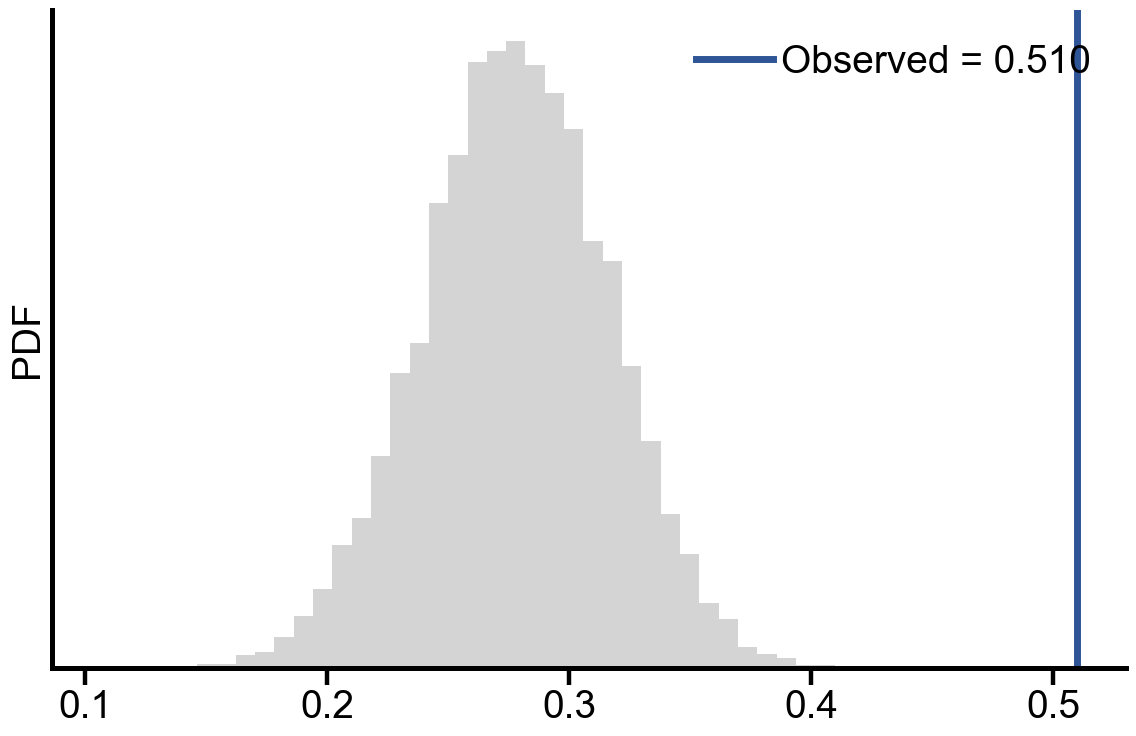

Observed Mean: 0.5000, Random Mean:0.1810,p-value: 0.0001
Z-score: 8.0481


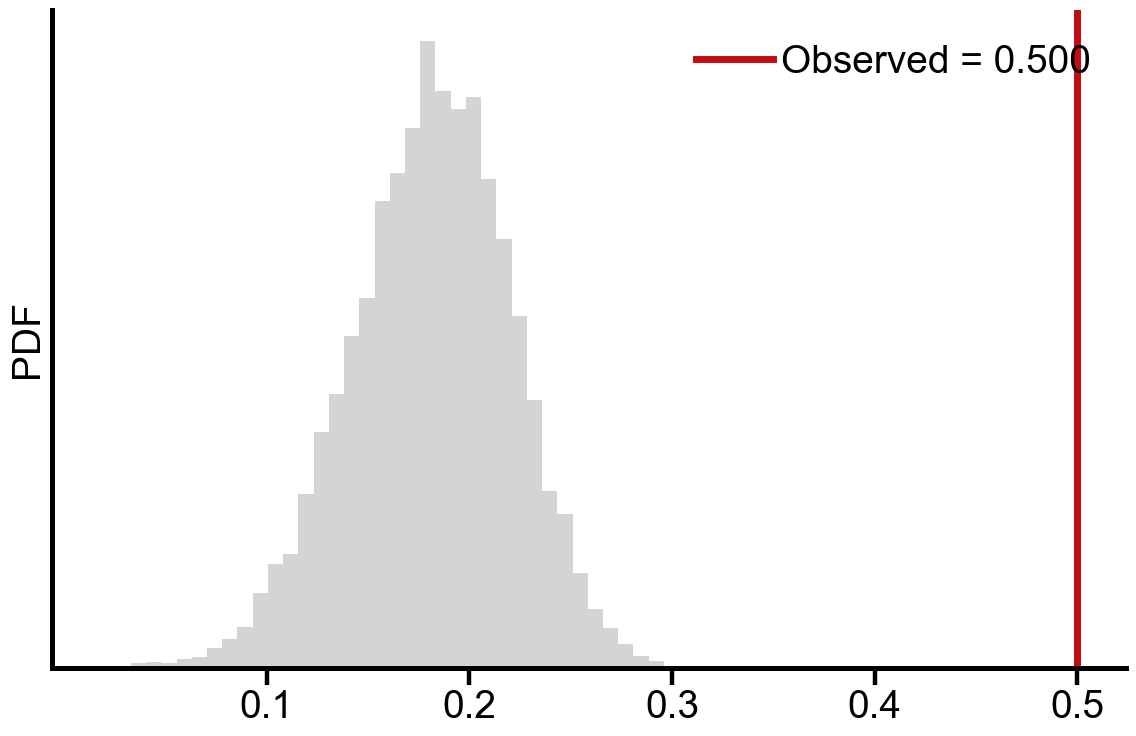

In [ ]:
set_panel_style(scale=4)

fig, ax = plt.subplots(figsize=(12, 8))
hist_color = "#D0D0D0"   # light gray
complex_line  = "#C40A13"   # deep red
simple_line   = "#2F5597"   # deep blue
n_perm = 10000


simple_mean = 0.51
complex_mean = 0.50

ax.hist([a[0] for a in random_correlations], bins=40, color=hist_color, alpha=0.9, edgecolor="none")
ax.axvline(simple_mean, color=simple_line, linewidth=5,
           label=rf"Observed = {simple_mean:.3f}")

ax.set_ylabel("PDF")
ax.legend(frameon=False, handletextpad=0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="y", left=False, labelleft=False)

ax.set_xticks([0.1, 0.2, 0.3, 0.4, 0.5])

random_means = [a[0] for a in random_correlations]
p_mean = (np.sum(np.array(random_means) >= simple_mean) + 1) / (n_perm + 1)
print(f"Observed Mean: {simple_mean:.4f}, Random Mean:{np.mean(random_means):.4f},p-value: {p_mean:.4f}")
z_mean = (simple_mean - np.mean(random_means)) / np.std(random_means, ddof=1)
print(f"Z-score: {z_mean:.4f}")

plt.tight_layout()
#fig.savefig("Supp_Figure8_N20.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.show()


fig, ax = plt.subplots(figsize=(12, 8))


ax.hist([a[1] for a in random_correlations], bins=40, color=hist_color, alpha=0.9, edgecolor="none")
ax.axvline(complex_mean, color=complex_line, linewidth=5,
           label=rf"Observed = {complex_mean:.3f}")

ax.set_ylabel("PDF")
ax.legend(frameon=False, handletextpad=0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="y", left=False, labelleft=False)
ax.set_xticks([0.1, 0.2, 0.3, 0.4, 0.5])
random_means = [a[1] for a in random_correlations]
p_mean = (np.sum(np.array(random_means) >= complex_mean) + 1) / (n_perm + 1)
print(f"Observed Mean: {complex_mean:.4f}, Random Mean:{np.mean(random_means):.4f},p-value: {p_mean:.4f}")
z_mean = (complex_mean - np.mean(random_means)) / np.std(random_means, ddof=1)
print(f"Z-score: {z_mean:.4f}")

#fig.savefig("Supp_Figure8_N400.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.tight_layout()
plt.show()

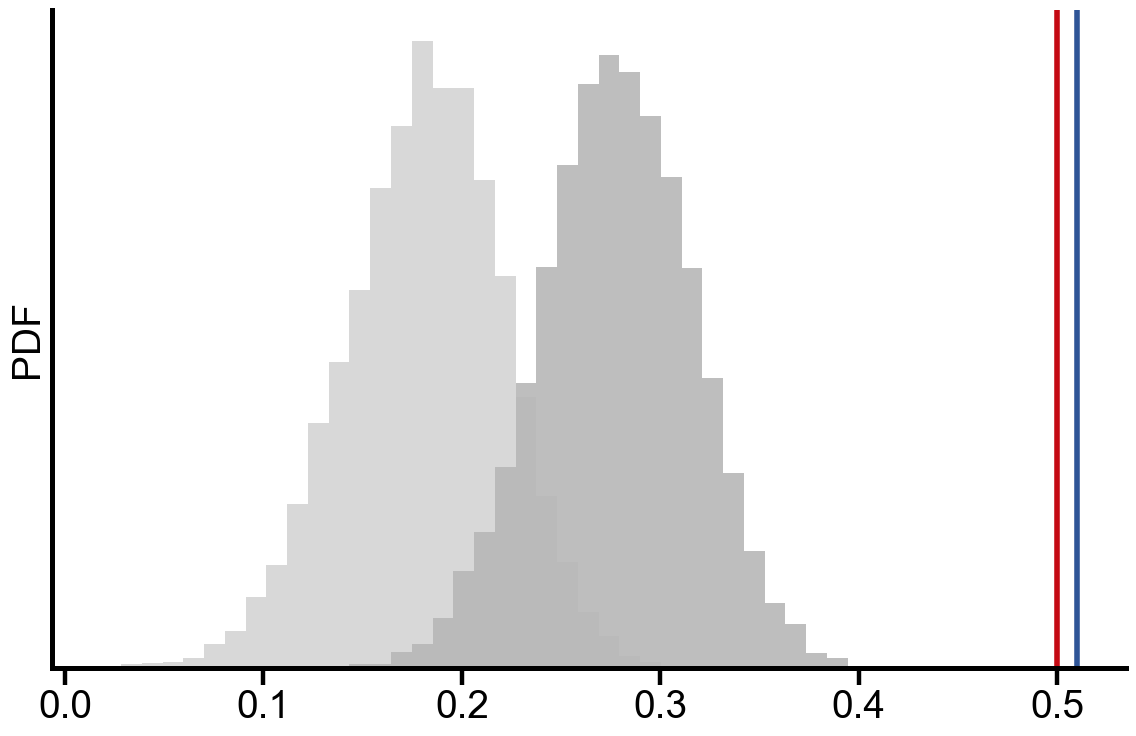

In [ ]:
set_panel_style(scale=4)

fig, ax = plt.subplots(figsize=(12, 8))

simple = np.array([a[0] for a in random_correlations])
complex_ = np.array([a[1] for a in random_correlations])

bins = np.linspace(
    min(simple.min(), complex_.min()),
    max(simple.max(), complex_.max()),
    40
)

# Random distributions
ax.hist(
    simple,
    bins=bins,
    density=True,
    color="#707070",
    alpha=0.45,
    edgecolor="none",
)

ax.hist(
    complex_,
    bins=bins,
    density=True,
    color="#B8B8B8",
    alpha=0.55,
    edgecolor="none",
)

# Observed
ax.axvline(
    simple_mean,
    color=simple_line,
    linewidth=4
)

ax.axvline(
    complex_mean,
    color=complex_line,
    linewidth=4
)

ax.set_ylabel("PDF")

ax.tick_params(axis="y", left=False, labelleft=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
#fig.savefig("Supp_Figure8_shuffled_edges.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.show()